# TP2 - Clasificación de Texto con un MLP

Dataset: **20 Newsgroups** (~18.000 posts de foros de Usenet, clasificados en 20 categorías).

Esta notebook parte de la del TP1 (Regresión Softmax): se reutiliza la carga de datos, el preprocesamiento, TF-IDF y el loop de entrenamiento.


## 0. Setup

In [1]:
!pip install -q mlflow optuna


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 1.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 57.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 64.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 30.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 20.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1

In [2]:
import re
import time
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from torch.utils.tensorboard import SummaryWriter
import mlflow
import mlflow.pytorch
import optuna

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)


Usando dispositivo: cpu


In [3]:
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

## 1. Datos: 20 Newsgroups

Usamos `remove=('headers', 'footers', 'quotes')` para sacar metadata que haría el problema "demasiado fácil" (por ejemplo, el header a veces incluye el nombre del newsgroup).

In [4]:
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test  = fetch_20newsgroups(subset="test",  remove=("headers", "footers", "quotes"))

class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
print(f"Clases ({NUM_CLASSES}):", class_names)
print(f"\nTrain: {len(newsgroups_train.data)} documentos | Test: {len(newsgroups_test.data)} documentos")

print("\n--- Ejemplo de documento ---")
print("Categoría:", class_names[newsgroups_train.target[0]])
print(newsgroups_train.data[0][:500])


Clases (20): ['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']

Train: 11314 documentos | Test: 7532 documentos

--- Ejemplo de documento ---
Categoría: rec.autos
I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.


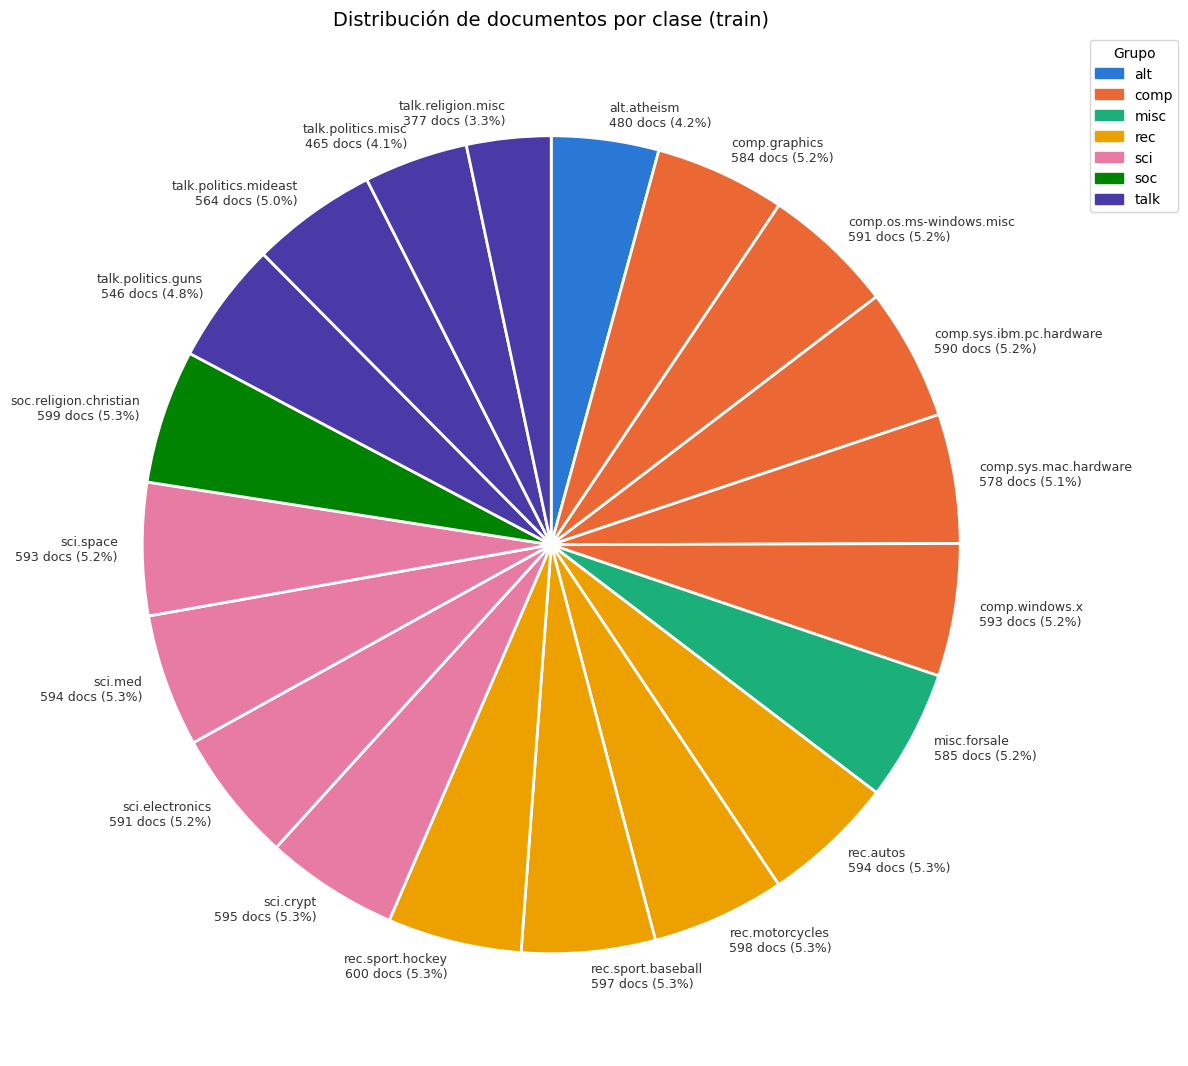

In [5]:
# Cantidad de documentos de cada clase en el set de entrenamiento
counts = np.bincount(newsgroups_train.target, minlength=NUM_CLASSES)
porcentajes = counts / counts.sum() * 100

# Cada porción se colorea según su grupo temático (el prefijo del nombre: comp, rec, sci, ...)
GROUP_COLORS = {
    "alt": "#2a78d6", "comp": "#eb6834", "misc": "#1baf7a", "rec": "#eda100",
    "sci": "#e87ba4", "soc": "#008300", "talk": "#4a3aa7",
}
colors = [GROUP_COLORS[name.split(".")[0]] for name in class_names]
labels = [f"{name}\n{c} docs ({p:.1f}%)" for name, c, p in zip(class_names, counts, porcentajes)]

fig, ax = plt.subplots(figsize=(12, 12))
ax.pie(
    counts,
    labels=labels,
    colors=colors,
    startangle=90,
    counterclock=False,
    labeldistance=1.06,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 9, "color": "#333333"},
)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in GROUP_COLORS.values()]
ax.legend(handles, GROUP_COLORS.keys(), title="Grupo", loc="upper left", bbox_to_anchor=(1.02, 1))
ax.set_title("Distribución de documentos por clase (train)", fontsize=14)
plt.tight_layout()
plt.show()


## 2. Preprocesamiento configurable

Vamos a armar una función de preprocesamiento con estos hiperparámetros (todos van a formar parte de la búsqueda de Optuna más adelante):

- `remove_stopwords` (`True`/`False`): sacar palabras muy frecuentes y poco informativas (`the`, `is`, `and`, ...).
- `normalization` (`"none"` / `"stem"` / `"lemmatize"`):
  - `"none"`: no se normaliza la palabra.
  - `"stem"`: **stemming** con Porter Stemmer — corta la palabra a una raíz heurística (`"running"` → `"run"`, a veces resultados no son palabras reales: `"studies"` → `"studi"`).
  - `"lemmatize"`: **lematización** con WordNet — lleva la palabra a su forma de diccionario (`"running"` → `"run"`, `"studies"` → `"study"`), más lenta pero más "correcta" lingüísticamente.

### TODO 1: completar `preprocess_text`

Pasos esperados:
1. Tokenizar el texto con `word_tokenize`.
2. Pasar todo a minúsculas y quedarse solo con tokens alfabéticos (`token.isalpha()`), para descartar números y puntuación.
3. Si `remove_stopwords` es `True`, sacar los tokens que estén en el set de stopwords.
4. Según `normalization`, aplicar `stemmer.stem(token)`, `lemmatizer.lemmatize(token)`, o dejar el token igual.
5. Devolver los tokens unidos con espacios (un string, para poder pasárselo después a `TfidfVectorizer`).

In [6]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()


def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]

    # TODO: si remove_stopwords es True, filtrar los tokens que están en STOP_WORDS
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]

    # TODO: aplicar la normalización correspondiente según el valor de `normalization`
    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]
    # si normalization == "none", no se hace nada más

    return " ".join(tokens)


In [7]:
# Sanity check: probamos las distintas combinaciones sobre una oración de ejemplo
ejemplo = "The researchers were studying the running processes and stopping conditions of the engines."
for norm in ["none", "stem", "lemmatize"]:
    for rm_sw in [False, True]:
        resultado = preprocess_text(ejemplo, remove_stopwords=rm_sw, normalization=norm)
        print(f"normalization={norm:10s} remove_stopwords={str(rm_sw):5s} -> {resultado}")


normalization=none       remove_stopwords=False -> the researchers were studying the running processes and stopping conditions of the engines
normalization=none       remove_stopwords=True  -> researchers studying running processes stopping conditions engines
normalization=stem       remove_stopwords=False -> the research were studi the run process and stop condit of the engin
normalization=stem       remove_stopwords=True  -> research studi run process stop condit engin
normalization=lemmatize  remove_stopwords=False -> the researcher were studying the running process and stopping condition of the engine
normalization=lemmatize  remove_stopwords=True  -> researcher studying running process stopping condition engine


## 3. Vectorización TF-IDF

Convertimos los textos preprocesados en vectores numéricos con `TfidfVectorizer`. Como el preprocesamiento (tokenización, stopwords, normalización) ya lo hicimos nosotros, acá solo controlamos:

- `ngram_range`: `(1,1)` solo unigramas, o `(1,2)` unigramas + bigramas (captura algo de contexto, ej. `"new york"`).
- `max_features`: tamaño máximo del vocabulario (se queda con los términos más frecuentes).
- `min_df`: un término tiene que aparecer en al menos `min_df` documentos para entrar al vocabulario (filtra términos rarísimos / errores de tipeo).

### TODO 2: completar `vectorize_data`

In [8]:
def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):
    # TODO: crear un TfidfVectorizer con los parámetros recibidos y ajustarlo (fit) sobre train_texts,
    # después transformar train_texts y test_texts con ese mismo vectorizer.
    vectorizer = TfidfVectorizer(ngram_range=ngram_range, max_features=max_features, min_df=min_df)
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)
    return X_train, X_test, vectorizer


In [9]:
# Sanity check rápido con pocos documentos
_sample_train = ["the cat sat on the mat", "dogs are running in the park", "cats and dogs are pets"]
_sample_test = ["the dog sat on the mat"]
_Xtr, _Xte, _vec = vectorize_data(_sample_train, _sample_test, ngram_range=(1, 1), max_features=50, min_df=2)
assert _Xtr is not None, "Completá vectorize_data"
print("Shape train:", _Xtr.shape, "| Shape test:", _Xte.shape)
print("Vocabulario (parcial):", list(_vec.vocabulary_.keys())[:10])


Shape train: (3, 3) | Shape test: (1, 3)
Vocabulario (parcial): ['the', 'dogs', 'are']


## 4. Modelo: MLP


In [10]:
ACTIVATIONS = {"relu": nn.ReLU, "tanh": nn.Tanh, "sigmoid": nn.Sigmoid}


class MLP(nn.Module):
    def __init__(self, input_dim, hidden_sizes, num_classes, activation="relu"):
        super().__init__()
        capas = []
        prev = input_dim
        for h in hidden_sizes:          # una vuelta por cada capa oculta
            capas.append(nn.Linear(prev, h))
            capas.append(ACTIVATIONS[activation]())
            prev = h
        capas.append(nn.Linear(prev, num_classes))  # salida, sin activación
        self.net = nn.Sequential(*capas)

    def forward(self, x):
        return self.net(x)

La clase MLP recibe el tamaño de la entrada, una lista hidden_sizes con la cantidad de neuronas de cada capa oculta, la cantidad de clases y el nombre de la función de activación. En el constructor se recorre hidden_sizes y por cada valor se agrega una capa lineal seguida de la activación elegida del diccionario ACTIVATIONS, usando prev para que cada capa conecte con el tamaño de la anterior. Al final se agrega la capa de salida, sin activación, y todas las capas se juntan con nn.Sequential, de modo que la entrada pasa por todas las capas en orden y la salida es un puntaje para cada clase.


In [11]:
# Sanity check: una red de 2 capas ocultas
_dummy = torch.randn(4, 50)
_model_check = MLP(input_dim=50, hidden_sizes=[32, 16], num_classes=20, activation="relu")
_out = _model_check(_dummy)
assert _out.shape == (4, 20), "Revisá MLP"
print(_model_check)
print("Shape de salida OK:", _out.shape)

MLP(
  (net): Sequential(
    (0): Linear(in_features=50, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=20, bias=True)
  )
)
Shape de salida OK: torch.Size([4, 20])


## 5. Entrenamiento (ya resuelto)

Dado que los datos vectorizados entran en memoria sin problema, armamos `DataLoader`s a partir de tensores densos. Logueamos loss y accuracy (train y validación) por época a TensorBoard, y a MLflow además los hiperparámetros y el modelo final.

In [12]:
%load_ext tensorboard


In [13]:
def to_tensor_dataset(X, y):
    X_dense = torch.tensor(X.toarray(), dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.long)
    return TensorDataset(X_dense, y_tensor)


def train_model(model, train_loader, val_loader, optimizer, epochs, writer=None, run_name="mlp", trial=None):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
        train_loss, train_acc = running_loss / total, correct / total

        model.eval()
        running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                loss = criterion(logits, yb)
                running_loss += loss.item() * xb.size(0)
                correct += (logits.argmax(dim=1) == yb).sum().item()
                total += xb.size(0)
        val_loss, val_acc = running_loss / total, correct / total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(f"[{run_name}] Epoch {epoch+1}/{epochs} - "
              f"train_loss: {train_loss:.4f} train_acc: {train_acc:.4f} - "
              f"val_loss: {val_loss:.4f} val_acc: {val_acc:.4f}")

        if writer is not None:
            writer.add_scalars("loss", {"train": train_loss, "val": val_loss}, epoch)
            writer.add_scalars("accuracy", {"train": train_acc, "val": val_acc}, epoch)
        mlflow.log_metric("train_loss", train_loss, step=epoch)
        mlflow.log_metric("val_loss", val_loss, step=epoch)
        mlflow.log_metric("train_acc", train_acc, step=epoch)
        mlflow.log_metric("val_acc", val_acc, step=epoch)

        # Pruning: si viene de Optuna, le pasamos la accuracy de validación de esta época
        # y cortamos el entrenamiento si Optuna decide que viene peor que los anteriores
        if trial is not None:
            trial.set_user_attr("history", history)
            trial.report(val_acc, epoch)
            if trial.should_prune():
                raise optuna.TrialPruned()

    return history


## 6. Búsqueda de hiperparámetros con Optuna


In [14]:
print("preprocesamiento para las 6 combinaciones posibles ")
preprocessed_cache = {}
for remove_stopwords in [False, True]:
    for normalization in ["none", "stem", "lemmatize"]:
        key = (remove_stopwords, normalization)
        train_proc = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_train.data]
        test_proc  = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_test.data]
        preprocessed_cache[key] = (train_proc, test_proc)
        print("  listo:", key)


preprocesamiento para las 6 combinaciones posibles 
  listo: (False, 'none')
  listo: (False, 'stem')
  listo: (False, 'lemmatize')
  listo: (True, 'none')
  listo: (True, 'stem')
  listo: (True, 'lemmatize')


In [15]:
def objective(trial):
    # Hiperparámetros del TP1
    remove_stopwords = trial.suggest_categorical("remove_stopwords", [False, True])
    normalization = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram_range = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    ngram_range_tuple = (1, 1) if ngram_range == "1gram" else (1, 2)
    max_features = trial.suggest_categorical("max_features", [5000, 10000, 20000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])

    # Arquitectura del MLP
    n_layers = trial.suggest_int("n_layers", 1, 3)
    hidden_sizes = [trial.suggest_categorical(f"n_units_l{i}", [64, 128, 256, 512]) for i in range(n_layers)]
    activation = trial.suggest_categorical("activation", ["relu", "tanh", "sigmoid"])

    # Optimizador y parámetros
    optimizer_name = trial.suggest_categorical("optimizer", ["Adam", "RMSprop", "SGD"])

    train_texts, test_texts = preprocessed_cache[(remove_stopwords, normalization)]
    # se parte de una porción de los datos como validación para la búsqueda
    tr_texts, val_texts, tr_labels, val_labels = train_test_split(
        train_texts, newsgroups_train.target, test_size=0.2, random_state=SEED,
        stratify=newsgroups_train.target,
    )

    X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram_range_tuple, max_features, min_df)
    train_loader = DataLoader(to_tensor_dataset(X_tr, tr_labels), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(to_tensor_dataset(X_val, val_labels), batch_size=batch_size, shuffle=False)

    model = MLP(X_tr.shape[1], hidden_sizes, NUM_CLASSES, activation)

    if optimizer_name == "Adam":
        lr = trial.suggest_float("lr_Adam", 1e-4, 1e-2, log=True)
        beta1 = trial.suggest_float("adam_beta1", 0.8, 0.99)      # momento de orden 1
        beta2 = trial.suggest_float("adam_beta2", 0.9, 0.9999)    # momento de orden 2
        optimizer = optim.Adam(model.parameters(), lr=lr, betas=(beta1, beta2))
    elif optimizer_name == "RMSprop":
        lr = trial.suggest_float("lr_RMSprop", 1e-4, 1e-2, log=True)
        momentum = trial.suggest_float("rmsprop_momentum", 0.0, 0.9)  # momento de orden 1
        alpha = trial.suggest_float("rmsprop_alpha", 0.9, 0.99)       # momento de orden 2
        optimizer = optim.RMSprop(model.parameters(), lr=lr, momentum=momentum, alpha=alpha)
    else:
        lr = trial.suggest_float("lr_SGD", 1e-2, 1.0, log=True)
        momentum = trial.suggest_float("sgd_momentum", 0.0, 0.99)     # momento de orden 1
        optimizer = optim.SGD(model.parameters(), lr=lr, momentum=momentum)


    start = time.perf_counter()
    try:
        history = train_model(model, train_loader, val_loader, optimizer, epochs=5,
                              run_name=f"trial_{trial.number}", trial=trial)
    finally:
        trial.set_user_attr("train_time_s", time.perf_counter() - start)

    return history["val_acc"][-1]


study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1),
)
study.optimize(objective, n_trials=40)

print("Mejores hiperparámetros:", study.best_params)
print("Mejor accuracy de validación:", study.best_value)


[I 2026-10-22 01:43:27,965] A new study created in memory with name: no-name-a29d498e-b704-4ea0-a556-df2239e0997f


[trial_0] Epoch 1/5 - train_loss: 2.7878 train_acc: 0.1766 - val_loss: 2.3321 val_acc: 0.3624


2026/10/22 01:43:51 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/22 01:43:51 INFO mlflow.store.db.utils: Updating database tables


[trial_0] Epoch 2/5 - train_loss: 1.7442 train_acc: 0.5575 - val_loss: 1.4499 val_acc: 0.6288
[trial_0] Epoch 3/5 - train_loss: 1.1168 train_acc: 0.7114 - val_loss: 1.2008 val_acc: 0.6584
[trial_0] Epoch 4/5 - train_loss: 0.8409 train_acc: 0.7670 - val_loss: 1.0760 val_acc: 0.6779


[I 2026-10-22 01:44:27,355] Trial 0 finished with value: 0.6866990720282811 and parameters: {'remove_stopwords': True, 'normalization': 'none', 'ngram_range': '1gram', 'max_features': 5000, 'min_df': 2, 'batch_size': 32, 'n_layers': 1, 'n_units_l0': 512, 'activation': 'sigmoid', 'optimizer': 'RMSprop', 'lr_RMSprop': 0.0010677482709481358, 'rmsprop_momentum': 0.5331731119758383, 'rmsprop_alpha': 0.9041805371447998}. Best is trial 0 with value: 0.6866990720282811.


...

[trial_37] Epoch 5/5 - train_loss: 0.4115 train_acc: 0.9113 - val_loss: 0.8645 val_acc: 0.7543
[trial_38] Epoch 1/5 - train_loss: 2.7612 train_acc: 0.4770 - val_loss: 2.3961 val_acc: 0.6527


[I 2026-10-22 02:30:22,727] Trial 38 pruned. 


[trial_38] Epoch 2/5 - train_loss: 1.9501 train_acc: 0.7195 - val_loss: 1.6792 val_acc: 0.6986
[trial_39] Epoch 1/5 - train_loss: 2.9994 train_acc: 0.0590 - val_loss: 2.9825 val_acc: 0.0999


[I 2026-10-22 02:31:03,377] Trial 39 pruned. 


[trial_39] Epoch 2/5 - train_loss: 2.9471 train_acc: 0.0883 - val_loss: 2.8650 val_acc: 0.1043
Mejores hiperparámetros: {'remove_stopwords': True, 'normalization': 'stem', 'ngram_range': '1gram', 'max_features': 20000, 'min_df': 1, 'batch_size': 128, 'n_layers': 1, 'n_units_l0': 512, 'activation': 'tanh', 'optimizer': 'RMSprop', 'lr_RMSprop': 0.0005039159941357251, 'rmsprop_momentum': 0.5483339605894613, 'rmsprop_alpha': 0.9678720626886999}
Mejor accuracy de validación: 0.7587273530711445


La función objective arma cada prueba de Optuna. Primero elige los mismos hiperparámetros del TP1 (stopwords, normalización, n-gramas, max_features, min_df y batch size), después la arquitectura del MLP (cantidad de capas ocultas, neuronas de cada capa y activación) y por último el optimizador. Cada optimizador tiene sus propios parámetros, así que Optuna elige solo los del que haya salido. Si sale Adam elige el learning rate, beta1 y beta2. Si sale RMSprop elige el learning rate, momentum y alpha. Y si sale SGD elige el learning rate y momentum. A SGD se le da un rango de learning rate más alto porque no ajusta solo el tamaño del paso. Con eso se arma el modelo, se entrena 5 épocas con el 20% del train como validación y se devuelve la accuracy de validación final, guardando además cuánto tardó. Para el pruning, la función train_model ahora recibe el trial y al terminar cada época le pasa la accuracy de validación a Optuna. El MedianPruner compara ese valor con la mediana de las pruebas anteriores en la misma época y, si viene peor, corta la prueba. Las primeras 5 pruebas y la primera época nunca se cortan, para tener con qué comparar. El sampler tiene semilla fija para que al volver a correr se prueben las mismas combinaciones.
